# SWYNEX Exploratory Data Analysis

## Project Overview

This project was completed as part of the SWYNEX Data Analyst Internship.

The objective of this task is to perform Exploratory Data Analysis (EDA) on the cleaned Titanic dataset and identify useful patterns, trends, and insights.

## Analysis Performed

- Dataset overview and descriptive statistics
- Overall survival rate analysis
- Survival rate by gender
- Survival rate by passenger class
- Age distribution analysis
- Fare distribution and outlier analysis
- Family size and survival analysis

## Tools Used

- Python
- Pandas
- Matplotlib
- Google Colab

In [5]:
from google.colab import files

uploaded = files.upload()

Saving titanic_cleaned.csv to titanic_cleaned.csv


In [6]:
import pandas as pd

df = pd.read_csv("titanic_cleaned.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    object 
 11  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print(gender_survival)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


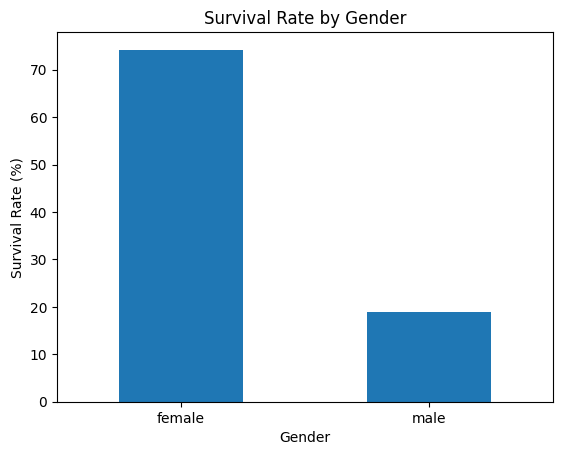

In [10]:
gender_survival.plot(kind="bar")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [11]:
class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print(class_survival)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


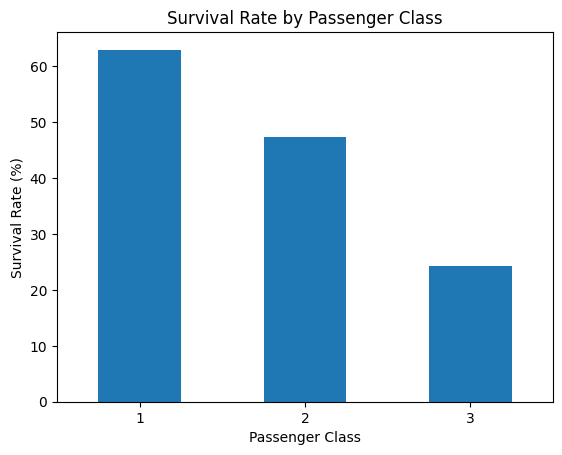

In [12]:
class_survival.plot(kind="bar")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()

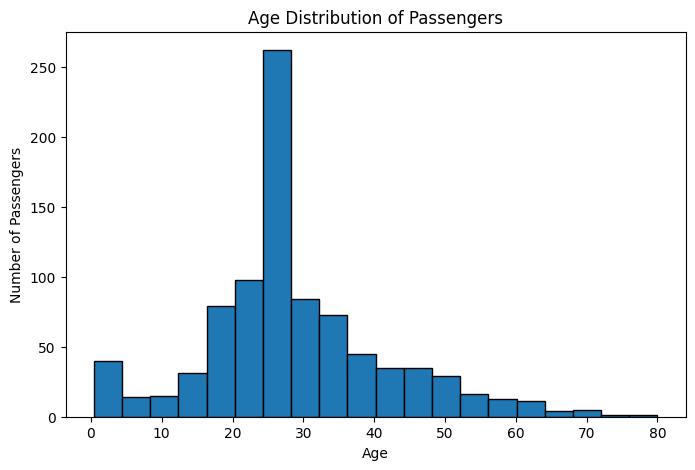

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

In [14]:
age_groups = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 30, 50, 80],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

print(age_groups.value_counts().sort_index())

Age
Child           69
Teenager        70
Young Adult    447
Adult          241
Senior          64
Name: count, dtype: int64


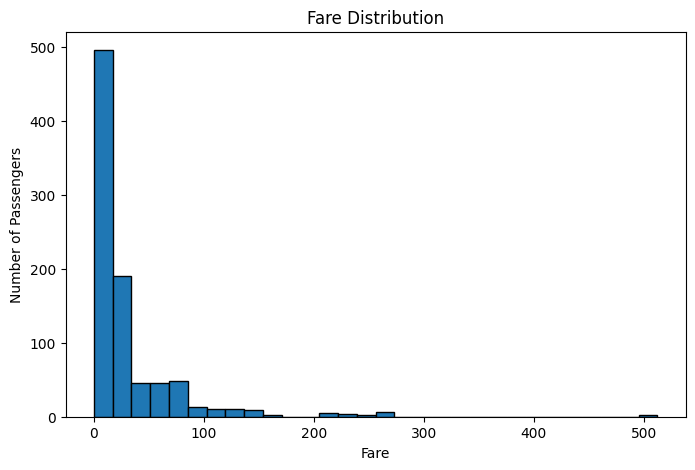

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(df["Fare"], bins=30, edgecolor="black")

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.show()

In [16]:
print("Fare statistics:")
print(df["Fare"].describe())

Fare statistics:
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


In [17]:
print("Passengers with fares above 100:")
print((df["Fare"] > 100).sum())

Passengers with fares above 100:
53


In [18]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

family_survival = df.groupby("FamilySize")["Survived"].mean() * 100

print(family_survival)

FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


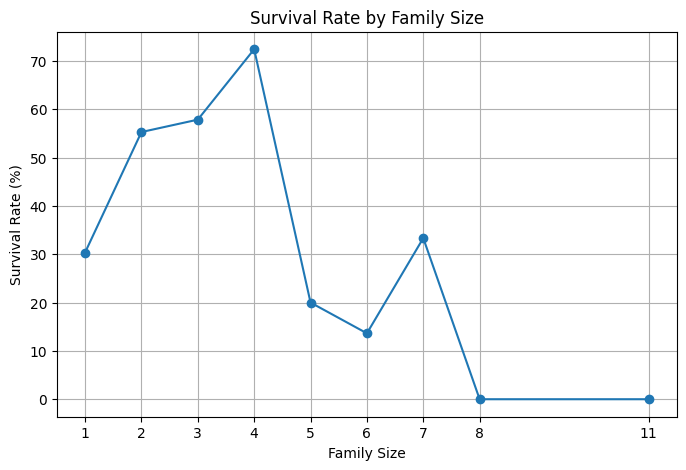

In [19]:
plt.figure(figsize=(8, 5))

family_survival.plot(kind="line", marker="o")

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate (%)")
plt.xticks(family_survival.index)
plt.grid(True)
plt.show()

## Key Insights

1. Approximately 38.4% of passengers survived.
2. Female passengers had a much higher survival rate (74.2%) than male passengers (18.9%).
3. First-class passengers had the highest survival rate (63.0%), while third-class passengers had the lowest (24.2%).
4. Young adults were the largest passenger age group, with 447 passengers.
5. Fare values were strongly right-skewed, with a maximum fare of 512.33 and 53 passengers paying more than 100.
6. Small-to-moderate family groups generally showed higher survival rates than very large family groups.